<a href="https://colab.research.google.com/github/Varshiireddy/nfl-win-probability/blob/main/notebooks/day1_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q nflreadpy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nflreadpy as nfl

In [3]:
KEEP = ["game_id", "season", "season_type", "play_type", "home_team", "away_team",
        "posteam", "qtr", "game_seconds_remaining", "yardline_100",
        "total_home_score", "total_away_score", "result"]

parts = []
for season in range(2015, 2026):
    parts.append(nfl.load_pbp([season]).select(KEEP).to_pandas())
    print("loaded", season)

pbp = pd.concat(parts, ignore_index=True)
pbp.shape

loaded 2015
loaded 2016
loaded 2017
loaded 2018
loaded 2019
loaded 2020
loaded 2021
loaded 2022
loaded 2023
loaded 2024
loaded 2025


(532376, 13)

In [4]:
pbp.head()

,game_id,season,season_type,play_type,home_team,away_team,posteam,qtr,game_seconds_remaining,yardline_100,total_home_score,total_away_score,result
0,2015_01_BAL_DEN,2015,REG,None,DEN,BAL,None,1.0,3600.0,NaN,0.0,0.0,6
1,2015_01_BAL_DEN,2015,REG,kickoff,DEN,BAL,BAL,1.0,3600.0,35.0,0.0,0.0,6
2,2015_01_BAL_DEN,2015,REG,pass,DEN,BAL,BAL,1.0,3600.0,80.0,0.0,0.0,6
3,2015_01_BAL_DEN,2015,REG,run,DEN,BAL,BAL,1.0,3573.0,77.0,0.0,0.0,6
4,2015_01_BAL_DEN,2015,REG,pass,DEN,BAL,BAL,1.0,3532.0,75.0,0.0,0.0,6


In [5]:
df = pbp[(pbp["season_type"] == "REG") & pbp["posteam"].notna()].copy()

df["home_lead"]      = df["total_home_score"] - df["total_away_score"]
df["mins_left"]      = df["game_seconds_remaining"] / 60
df["home_has_ball"]  = (df["posteam"] == df["home_team"]).astype(float)
df["home_field_pos"] = np.where(df["home_has_ball"] == 1,
                                df["yardline_100"], 100 - df["yardline_100"])

FEATURES = ["home_lead", "mins_left", "home_has_ball", "home_field_pos"]
df = df.dropna(subset=FEATURES + ["result"])

In [6]:
train = df[df["season"] <= 2022]
test  = df[df["season"] >= 2023]

X_train, y_train = train[FEATURES].to_numpy(), train["result"].to_numpy()
X_test,  y_test  = test[FEATURES].to_numpy(),  test["result"].to_numpy()

In [7]:
mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - mu) / sd
X_test_s  = (X_test - mu) / sd

epoch   0   loss 198.36
epoch  50   loss 97.81
epoch 100   loss 97.81
epoch 150   loss 97.81
epoch 200   loss 97.81
epoch 250   loss 97.81


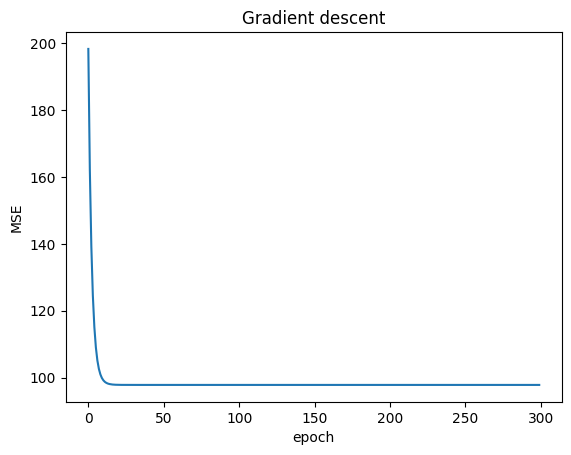

home_lead       9.887
mins_left       0.409
home_has_ball   1.138
home_field_pos  -0.770
bias            1.509


In [8]:
def fit_gd(X, y, lr=0.1, epochs=300):
    n, d = X.shape              # n = number of plays, d = 4 features
    w = np.zeros(d)             # start all 4 weights at 0
    b = 0.0                     # start bias at 0
    losses = []

    for i in range(epochs):
        # 1. predict: y_hat = X·w + b
        y_hat = X @ w + b

        # 2. error: how wrong each prediction is
        error = y_hat - y

        # 3. loss: mean squared error
        loss = np.mean(error ** 2)
        losses.append(loss)

        # 4. gradients
        dw = (2 / n) * (X.T @ error)
        db = (2 / n) * np.sum(error)

        # 5. update: step downhill
        w = w - lr * dw
        b = b - lr * db

        if i % 50 == 0:
            print(f"epoch {i:3d}   loss {loss:.2f}")

    return w, b, losses


w, b, losses = fit_gd(X_train_s, y_train)

plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Gradient descent")
plt.show()

for name, weight in zip(FEATURES, w):
    print(f"{name:15s} {weight:.3f}")
print(f"{'bias':15s} {b:.3f}")

In [9]:
from sklearn.linear_model import LinearRegression

# scikit-learn's version, trained on the SAME standardized data
sk = LinearRegression()
sk.fit(X_train_s, y_train)

# side-by-side comparison
compare = pd.DataFrame({
    "my gradient descent": np.r_[b, w],
    "scikit-learn":        np.r_[sk.intercept_, sk.coef_],
}, index=["bias"] + FEATURES)

compare["difference"] = (compare["my gradient descent"] - compare["scikit-learn"]).abs()
print(compare.round(4))

# automatic pass/fail check
if np.allclose(np.r_[b, w], np.r_[sk.intercept_, sk.coef_], atol=1e-3):
    print("\n✅ Your gradient descent matches scikit-learn")
else:
    print("\n❌ Not matching yet. Try more epochs or check your gradient formulas")

                my gradient descent  scikit-learn  difference
bias                         1.5094        1.5094         0.0
home_lead                    9.8867        9.8867         0.0
mins_left                    0.4088        0.4088         0.0
home_has_ball                1.1381        1.1381         0.0
home_field_pos              -0.7703       -0.7703         0.0

✅ Your gradient descent matches scikit-learn


In [10]:
# 1. predict the final margin for every play in 2023–2025
pred_test = X_test_s @ w + b

# 2. baseline: always guess the average margin from training data
baseline = np.full_like(y_test, y_train.mean())

# 3. RMSE = typical size of the error, in points
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

print(f"Baseline RMSE (always guess average): {rmse(y_test, baseline):.2f} points")
print(f"My model RMSE:                        {rmse(y_test, pred_test):.2f} points")

Baseline RMSE (always guess average): 14.21 points
My model RMSE:                        9.86 points


qtr
1.0    10.50
2.0     8.80
3.0     6.65
4.0     3.76
5.0     3.25
Name: abs_error, dtype: float64


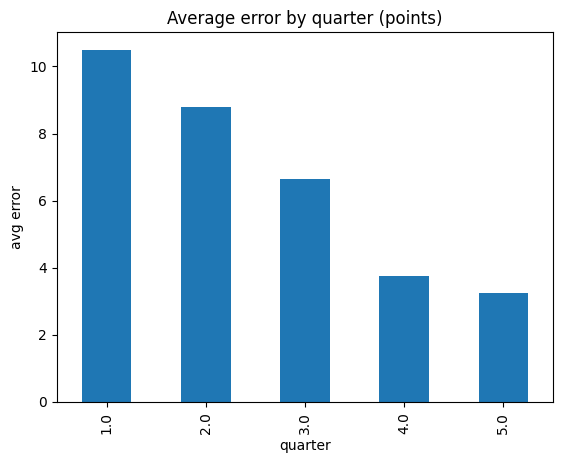

In [11]:
test_results = test.copy()
test_results["abs_error"] = np.abs(y_test - pred_test)

by_qtr = test_results.groupby("qtr")["abs_error"].mean().round(2)
print(by_qtr)

by_qtr.plot.bar(title="Average error by quarter (points)")
plt.xlabel("quarter"); plt.ylabel("avg error"); plt.show()